# LSTM: 7-Day Groundwater Level Forecasting

Daily dataset (53 wells, 2019-2023). The LSTM reads 30 days of features per well and predicts the change in groundwater level for each of the next 7 days.

Split by year: train = 2019-2021, val = 2022, test = 2023. Baseline is persistence (predict no change).

# Downloading the Data

In [1]:
!git clone https://github.com/Break-Through-Tech/Microsoft-4B-groundwater-timeseries-prediction-using-AI.git

Cloning into 'Microsoft-4B-groundwater-timeseries-prediction-using-AI'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (48/48), done.
remote: Total 50 (delta 23), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 7.20 MiB | 3.13 MiB/s, done.
Resolving deltas: 100% (23/23), done.
Updating files: 100% (11/11), done.


In [2]:
%cd Microsoft-4B-groundwater-timeseries-prediction-using-AI

/content/Microsoft-4B-groundwater-timeseries-prediction-using-AI


In [3]:
%cd notebooks

/content/Microsoft-4B-groundwater-timeseries-prediction-using-AI/notebooks


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Daily Dataset

In [5]:
df_daily = pd.read_csv("../data/svn_regional_53_wells_daily_2019_2023.csv")
df_daily.shape

/tmp/ipykernel_413/2305135731.py:1: DtypeWarning: Columns (58) have mixed types. Specify dtype option on import or set low_memory=False.
  df_daily = pd.read_csv("../data/svn_regional_53_wells_daily_2019_2023.csv")


(96778, 65)

## Daily Dataset Cleaning

Same cleaning as the shared EDA: drop sparse columns, interpolate numeric gaps.

In [6]:
df_daily = df_daily.drop(columns=['aggregated_from_n_values', 'status', 'aquifer_name', 'confinement'])

dfdaily_missing_cols = df_daily.columns[df_daily.isna().any()]
numeric_cols = df_daily[dfdaily_missing_cols].select_dtypes(include=np.number).columns
df_daily[numeric_cols] = df_daily[numeric_cols].interpolate()

df_daily.shape

(96778, 61)

## Daily Feature Engineering

Same features as `feature_engineering.ipynb`.

In [7]:
# date to datetime, sort by well + date
df_daily_fe = df_daily.copy()
df_daily_fe['date'] = pd.to_datetime(df_daily_fe['date'])
df_daily_fe.sort_values(by=['GROW_ID', 'date'], inplace=True)

# month + recharge season flag (oct-mar), wells fill up in winter
df_daily_fe['month_num'] = df_daily_fe['date'].dt.month
df_daily_fe['is_recharge_season'] = df_daily_fe['month_num'].isin([10, 11, 12, 1, 2, 3]).astype(int)

# precip mm/year -> mm/day
df_daily_fe['precip_mm'] = df_daily_fe['precipitation_mswep_mm_year-1'] / 365.25

# rain minus evaporation
df_daily_fe['water_balance_mm'] = df_daily_fe['precip_mm'] - df_daily_fe['actual_evapotranspiration_mm_year-1'] / 365.25

# rolling sums per well (30 / 90 days) so windows dont mix wells
target = 'groundwater_water_level_elevation_m_asl'
grouped_daily = df_daily_fe.groupby('GROW_ID')

df_daily_fe['precip_sum_30'] = grouped_daily['precip_mm'].transform(lambda x: x.rolling(30, min_periods=1).sum())
df_daily_fe['precip_sum_90'] = grouped_daily['precip_mm'].transform(lambda x: x.rolling(90, min_periods=1).sum())
df_daily_fe['water_balance_sum_90'] = grouped_daily['water_balance_mm'].transform(lambda x: x.rolling(90, min_periods=1).sum())

# past levels + how much it moved
df_daily_fe['level_lag_1'] = grouped_daily[target].shift(1)
df_daily_fe['level_lag_7'] = grouped_daily[target].shift(7)
df_daily_fe['level_lag_30'] = grouped_daily[target].shift(30)
df_daily_fe['level_diff_7'] = grouped_daily[target].diff(7)

# level vs the well's own avg, wells sit at diff elevations
df_daily_fe['level_anomaly'] = df_daily_fe[target] - df_daily_fe['groundwater_mean_m']

# drop first rows per well, no history so lags are NaN
df_daily_fe = df_daily_fe.dropna(subset=['level_lag_30'])
df_daily = df_daily_fe.copy()
print(df_daily.shape)

(95188, 73)


# LSTM: Long Short Term Memory

In [8]:
torch.manual_seed(42)
np.random.seed(42)

In [9]:
# copy of the daily data for the lstm and then sorting by well and date accordingly
lstm_df = df_daily.sort_values(['GROW_ID', 'date']).reset_index(drop=True)

# lvl moved since yesterday
lstm_df['change_1'] = lstm_df[target] - lstm_df['level_lag_1']

# doing the level vs the well's normal level, but in here the mean only uses the train years 2019-2021)
train_mean = lstm_df[lstm_df['date'] < '2022-01-01'].groupby('GROW_ID')[target].mean()
lstm_df['anomaly_train'] = lstm_df[target] - lstm_df['GROW_ID'].map(train_mean)

# 10 features, most of them come from our feature engineering
features = ['change_1',
            'level_diff_7',
            'anomaly_train',
            'precip_mm',
            'precip_sum_30',
            'precip_sum_90',
            'water_balance_mm',
            'water_balance_sum_90',
            'air_temperature_°C',
            'is_recharge_season']

print('Here the missing values is', lstm_df[features].isna().sum().sum())

Here the missing values is 0


In [10]:
# scale features to 0-1 instead of mean/std, lstm gates (sigmoid/tanh) work better with bounded input
# using only train rows so 2022 and 2023 dont leak in
is_train = lstm_df['date'] < '2022-01-01'
min_ = lstm_df.loc[is_train, features].min()
max_ = lstm_df.loc[is_train, features].max()
lstm_df[features] = (lstm_df[features] - min_) / (max_ - min_)

# windows: 30 days in, next 7 days out, one well at a time
# doing one well at a time so a window never mixes 2 different wells
X_seq = []
y_seq = []
window_info = []

for well in lstm_df['GROW_ID'].unique():
    well_df = lstm_df[lstm_df['GROW_ID'] == well]
    feats = well_df[features].values
    level = well_df[target].values
    dates = well_df['date'].values

    for i in range(len(well_df) - 36):
        x = feats[i:i+30]
        today = level[i+29]
        next_7 = level[i+30:i+37]
        X_seq.append(x)
        y_seq.append(next_7 - today)
        window_info.append([well, dates[i+29], dates[i+36], today])

X_seq = np.array(X_seq, dtype='float32')
y_seq = np.array(y_seq, dtype='float32')
window_info = pd.DataFrame(window_info, columns=['GROW_ID', 'date', 'end_date', 'level_today'])

print(X_seq.shape, y_seq.shape)

(93280, 30, 10) (93280, 7)


In [11]:
# split by year, train = 2019-2021, val = 2022, test = 2023
# end_date makes sure the 7 predicted days stay inside the same year
train_mask = (window_info['end_date'] < '2022-01-01').values
val_mask = ((window_info['date'] >= '2022-01-01') & (window_info['end_date'] < '2023-01-01')).values
test_mask = (window_info['date'] >= '2023-01-01').values

X_train = torch.tensor(X_seq[train_mask])
y_train = torch.tensor(y_seq[train_mask])
X_val = torch.tensor(X_seq[val_mask])
y_val = torch.tensor(y_seq[val_mask])
X_test = torch.tensor(X_seq[test_mask])
y_test = y_seq[test_mask]  # keeping this one numpy, using it for rmse later

print(len(X_train), len(X_val), len(X_test))

train_data = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_data, batch_size=256, shuffle=True)

54590 18974 18974


In [12]:
# lstm reads the 30 days in order, then a linear layer turns the last day into 7 predictions
class LSTMModel(nn.Module):
    def __init__(self, n_features, hidden_size):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, 7)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        return self.linear(out)

lstm_model = LSTMModel(n_features=10, hidden_size=64)
print(lstm_model)

LSTMModel(
  (lstm): LSTM(10, 64, batch_first=True)
  (linear): Linear(in_features=64, out_features=7, bias=True)
)


In [13]:
# huber loss is like mse but big outlier jumps count less, a few wells jump a lot in one day
loss_fn = nn.HuberLoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.0003)

train_losses = []
val_losses = []
best_val = 999999
epochs_no_improve = 0

for epoch in range(50):
    lstm_model.train()
    total_loss = 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        pred = lstm_model(xb)
        loss = loss_fn(pred, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    train_loss = total_loss / len(X_train)

    lstm_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(lstm_model(X_val), y_val).item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print('epoch', epoch + 1, 'train', round(train_loss, 4), 'val', round(val_loss, 4))

    # early stopping: save the best one, stop if val doesnt improve for 5 epochs
    if val_loss < best_val:
        best_val = val_loss
        epochs_no_improve = 0
        torch.save(lstm_model.state_dict(), 'best_lstm.pt')
    else:
        epochs_no_improve += 1
        if epochs_no_improve == 5:
            print('stopping early')
            break

lstm_model.load_state_dict(torch.load('best_lstm.pt'))

epoch 1 train 0.0786 val 0.0511
epoch 2 train 0.0736 val 0.0503
epoch 3 train 0.0708 val 0.0508
epoch 4 train 0.0694 val 0.0521
epoch 5 train 0.0683 val 0.0528
epoch 6 train 0.0672 val 0.0522
epoch 7 train 0.0664 val 0.0556
stopping early


<All keys matched successfully>

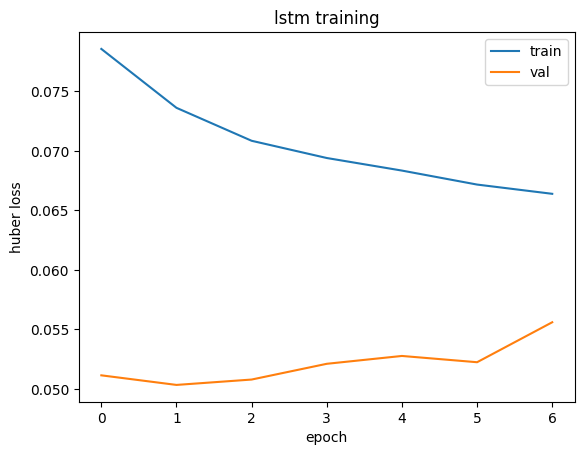

In [14]:
plt.plot(train_losses, label='train')
plt.plot(val_losses, label='val')
plt.title('lstm training')
plt.xlabel('epoch')
plt.ylabel('huber loss')
plt.legend()
plt.show()

## Test on 2023

In [15]:
# testing on 2023, model never saw this year
lstm_model.eval()
with torch.no_grad():
    lstm_pred = lstm_model(X_test).numpy()

# rmse per day, persistence = guessing no change at all
lstm_rmse = []
persistence_rmse = []
for d in range(7):
    lstm_rmse.append(np.sqrt(np.mean((lstm_pred[:, d] - y_test[:, d]) ** 2)))
    persistence_rmse.append(np.sqrt(np.mean(y_test[:, d] ** 2)))

results = pd.DataFrame({'day': range(1, 8), 'persistence': persistence_rmse, 'lstm': lstm_rmse})
results['better_%'] = (1 - results['lstm'] / results['persistence']) * 100
print(results.round(3))

# success criteria: within 30% of ground truth (20% stretch), averaged over the 7 days
level_today = window_info['level_today'][test_mask].values.reshape(-1, 1)
actual_level = level_today + y_test
predicted_level = level_today + lstm_pred
pct_error = np.mean(np.abs(predicted_level - actual_level) / actual_level, axis=1) * 100

print()
print('avg % error:', round(pct_error.mean(), 3))
print()
print('within 30%:', round((pct_error <= 30).mean() * 100, 1), '%')
print('within 20%:', round((pct_error <= 20).mean() * 100, 1), '%')

   day  persistence   lstm  better_%
0    1        0.273  0.296    -8.625
1    2        0.507  0.534    -5.292
2    3        0.707  0.729    -3.089
3    4        0.881  0.898    -1.925
4    5        1.034  1.051    -1.711
5    6        1.169  1.180    -0.879
6    7        1.290  1.302    -0.969

avg % error: 0.093

within 30%: 100.0 %
within 20%: 100.0 %
